In [21]:
!pip install opencv-python scikit-image

In [22]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import mean_squared_error as mse

1. Загрузка изображения в отттенках серого sar_1_gray.jpg.

In [23]:
image_gray = cv2.imread('sar_1_gray.jpg', cv2.IMREAD_GRAYSCALE)

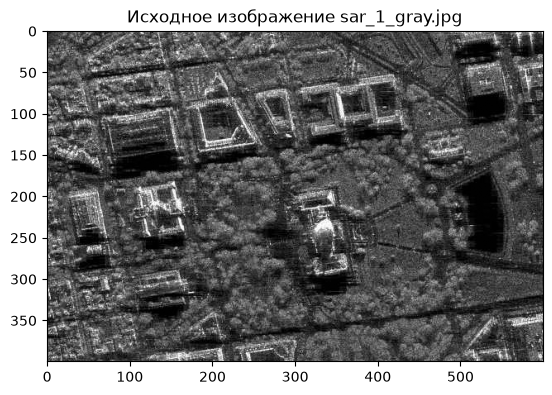

In [24]:
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение sar_1_gray.jpg')
plt.show();

2. Построение гистограммы

In [25]:
hist = cv2.calcHist([image_gray], [0], None, [256], [0, 256])

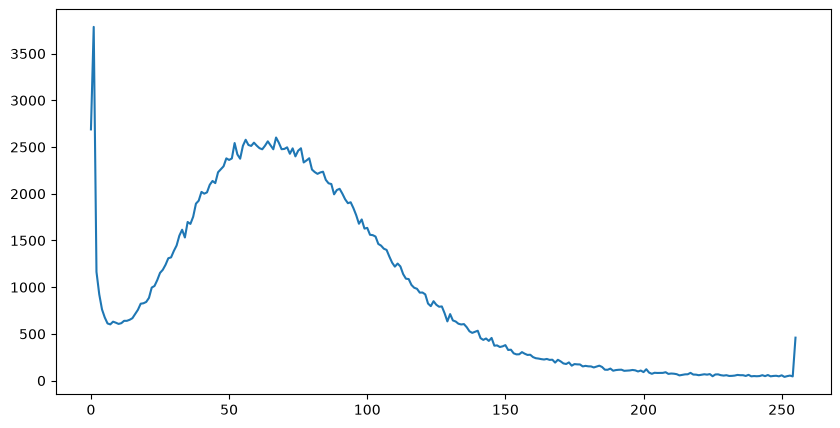

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(hist)
plt.show()

3. Реализация алгоритма гамма коррекции с параметром гамма <1, >1.

In [27]:
def gamma_correction(image, gamma):
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    return cv2.LUT(image, table)

gamma_low = gamma_correction(image_gray, 0.5)   # светлее
gamma_high = gamma_correction(image_gray, 2.0)  # темнее

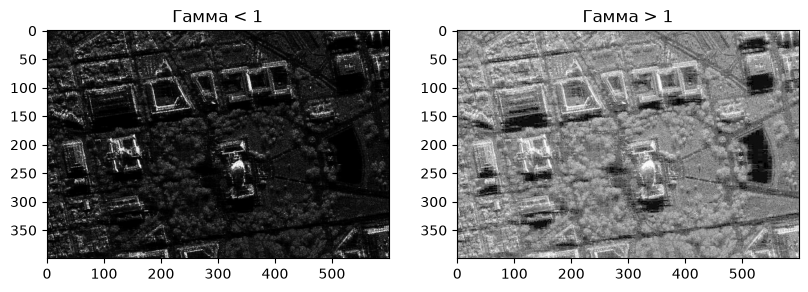

In [28]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 2), plt.imshow(gamma_low, cmap='gray'), plt.title('Гамма < 1')
plt.subplot(1, 3, 3), plt.imshow(gamma_high, cmap='gray'), plt.title('Гамма > 1')
plt.show()

4. Сравнение исходного изображения, скорректированного при помощи гамма-фильтра. MSE, SSIM.

In [29]:
mse_low = mse(image_gray, gamma_low)
ssim_low = ssim(image_gray, gamma_low, data_range=255)
mse_high = mse(image_gray, gamma_high)
ssim_high = ssim(image_gray, gamma_high, data_range=255)

print(f"Гамма < 1 (0.5): MSE = {mse_low:.2f}, SSIM = {ssim_low:.4f}")
print(f"Гамма > 1 (2.0): MSE = {mse_high:.2f}, SSIM = {ssim_high:.4f}")

Гамма < 1 (0.5): MSE = 2383.76, SSIM = 0.5270
Гамма > 1 (2.0): MSE = 3250.43, SSIM = 0.7875


   
5. Реализация алгоритма статистической цветокоррекции на основе статистики eq_gray.

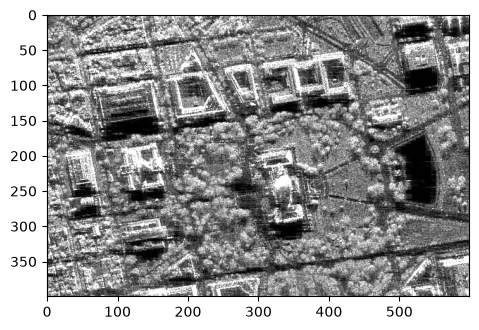

In [30]:
eq_gray = cv2.equalizeHist(image_gray)
mean_src, std_src = image_gray.mean(), image_gray.std()
mean_ref, std_ref = eq_gray.mean(), eq_gray.std()
corrected_stat = (image_gray.astype(np.float32) - mean_src) * (std_ref / std_src) + mean_ref
corrected_stat = np.clip(corrected_stat, 0, 255).astype(np.uint8)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 2), plt.imshow(corrected_stat, cmap='gray')
plt.show()

6. Тестирование работы алгоритмов пороговой фильтрации с различными параметрами.

Порог 50: количество белых пикселей = 169178
Порог 100: количество белых пикселей = 55653
Порог 150: количество белых пикселей = 13083
Порог 200: количество белых пикселей = 3830


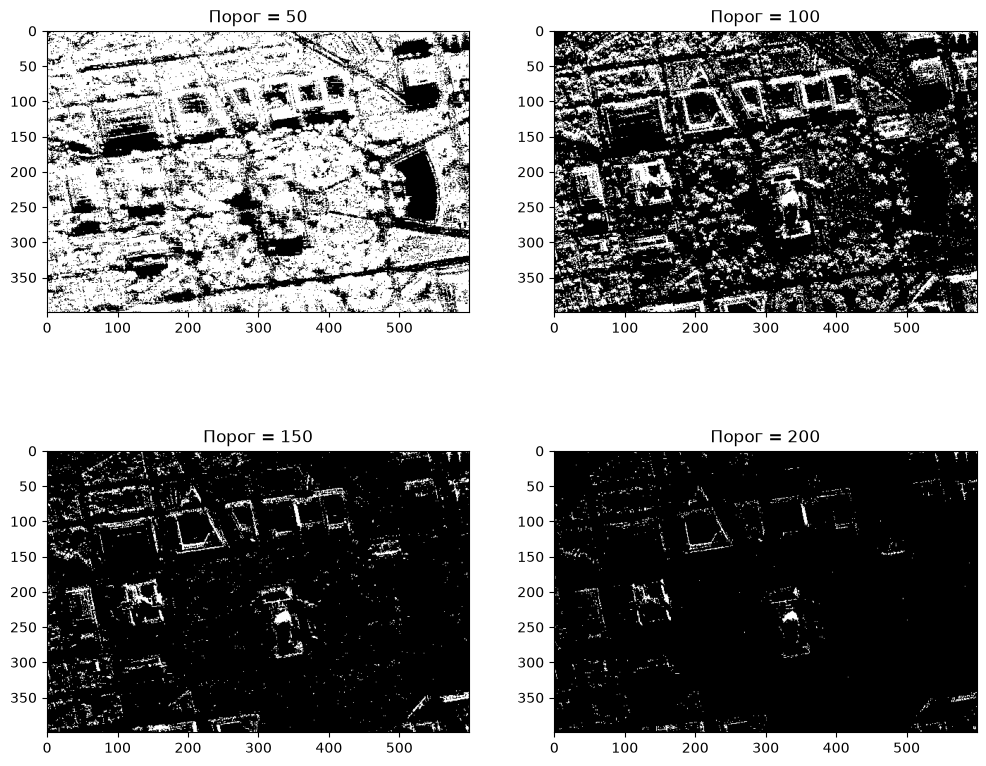

In [31]:
thresholds = [50, 100, 150, 200]
plt.figure(figsize=(12, 10))

for i, t in enumerate(thresholds):
    _, thresh_img = cv2.threshold(image_gray, t, 255, cv2.THRESH_BINARY)
    
    plt.subplot(2, 2, i+1)
    plt.imshow(thresh_img, cmap='gray')
    plt.title(f'Порог = {t}')
    white_pixels = np.sum(thresh_img == 255)
    print(f"Порог {t}: количество белых пикселей = {white_pixels}")

plt.show()